# 03 — Toronto building-height enrichment

## Purpose

This notebook enriches the baseline VoxCity building layer for the
**2 km × 2 km U of T pilot area** using the already-extracted
**City of Toronto 3D Massing** dataset.

The workflow is intentionally local and reproducible:

1. recreate the exact U of T pilot area;
2. load the baseline VoxCity pilot output from Notebook 02;
3. discover the extracted Toronto 3D Massing shapefile locally;
4. inspect the schema and identify a plausible building-height field;
5. clip the municipal building data to the pilot area;
6. clean the height values;
7. convert the municipal layer into a VoxCity-compatible format;
8. rebuild the same baseline VoxCity pilot;
9. replace/enrich the building layer;
10. compare baseline and enriched building-height grids;
11. save the enriched pilot outputs.

No web download is performed in this notebook.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from shapely.geometry import box
from voxcity.generator import (
    get_voxcity,
    save_voxcity,
    update_voxcity,
)

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

MASSING_EXTRACTED = (
    TORONTO_RAW
    / "3d_massing"
    / "extracted"
)

ENRICHED_DIR = (
    TORONTO_INTERIM
    / "voxcity_enriched"
)

ENRICHED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", PROJECT_ROOT)
print("3D Massing extracted folder:", MASSING_EXTRACTED)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
3D Massing extracted folder: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/3d_massing/extracted


## 2. Recreate the U of T pilot area

Notebook 02 used a **2 km × 2 km pilot square centered on the U of T campus**.

We recreate the same geometry from the saved campus-center point.

In [2]:
campus_center_path = (
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
)

if not campus_center_path.exists():
    raise FileNotFoundError(
        f"Campus center not found: {campus_center_path}"
    )

campus_center = gpd.read_file(
    campus_center_path
)

TARGET_CRS = campus_center.crs
PILOT_HALF_WIDTH_M = 1000

campus_x = campus_center.geometry.x.iloc[0]
campus_y = campus_center.geometry.y.iloc[0]

pilot_geometry = box(
    campus_x - PILOT_HALF_WIDTH_M,
    campus_y - PILOT_HALF_WIDTH_M,
    campus_x + PILOT_HALF_WIDTH_M,
    campus_y + PILOT_HALF_WIDTH_M,
)

pilot_area = gpd.GeoDataFrame(
    {
        "tile_id": ["UOFT_PILOT"],
    },
    geometry=[pilot_geometry],
    crs=TARGET_CRS,
)

print(
    "Pilot area:",
    round(
        pilot_area.geometry.area.iloc[0] / 1_000_000,
        3,
    ),
    "km²",
)

Pilot area: 4.0 km²


## 3. Load the baseline VoxCity pilot output

This is the saved baseline output from Notebook 02.

In [3]:
baseline_nc = (
    TORONTO_INTERIM
    / "voxcity_test"
    / "UOFT_PILOT_voxcity_initial.nc"
)

if not baseline_nc.exists():
    raise FileNotFoundError(
        f"Baseline VoxCity NetCDF not found: {baseline_nc}"
    )

baseline_ds = xr.open_dataset(
    baseline_nc
)

print("Baseline NetCDF loaded:")
print(baseline_nc)
print()
print(baseline_ds)

Baseline NetCDF loaded:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_test/UOFT_PILOT_voxcity_initial.nc

<xarray.Dataset> Size: 18MB
Dimensions:          (north: 408, east: 408, up: 63)
Coordinates:
  * north            (north) float64 3kB 2.5 7.5 12.5 ... 2.032e+03 2.038e+03
  * east             (east) float64 3kB 2.5 7.5 12.5 ... 2.032e+03 2.038e+03
  * up               (up) float64 504B 2.5 7.5 12.5 17.5 ... 302.5 307.5 312.5
Data variables:
    voxel            (north, east, up) int8 10MB ...
    building_height  (north, east) float64 1MB ...
    building_id      (north, east) float64 1MB ...
    land_cover       (north, east) int64 1MB ...
    dem              (north, east) float64 1MB ...
    canopy_top       (north, east) float64 1MB ...
    canopy_bottom    (north, east) float64 1MB ...
Attributes:
    axes:                north,east,up
    rotation_angle:      0.0
    meshsize:            5.0
    crs:                 EPSG:4326
   

## 4. Discover the extracted Toronto 3D Massing shapefile

The data have already been extracted locally, so we search recursively for
`.shp` files.

If multiple shapefiles are present, the notebook prefers one whose filename
contains `massing`.

In [4]:
if not MASSING_EXTRACTED.exists():
    raise FileNotFoundError(
        f"Extracted 3D Massing folder not found: {MASSING_EXTRACTED}"
    )

shapefiles = sorted(
    MASSING_EXTRACTED.rglob("*.shp")
)

if not shapefiles:
    raise FileNotFoundError(
        f"No shapefile found under: {MASSING_EXTRACTED}"
    )

print("Shapefiles found:")

for shp in shapefiles:
    print("-", shp)

preferred = [
    shp
    for shp in shapefiles
    if "massing" in shp.name.lower()
]

massing_shp = (
    preferred[0]
    if preferred
    else shapefiles[0]
)

print()
print("Using shapefile:")
print(massing_shp)

Shapefiles found:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/3d_massing/extracted/3DMassingShapefile_2025_WGS84.shp

Using shapefile:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/3d_massing/extracted/3DMassingShapefile_2025_WGS84.shp


## 5. Read and inspect the municipal building dataset

We inspect the schema before selecting a height field.

In [5]:
massing = gpd.read_file(
    massing_shp
)

print("Rows:", f"{len(massing):,}")
print("CRS :", massing.crs)

print()
print("Columns:")
print(list(massing.columns))

print()
print("Data types:")
print(massing.dtypes)

Rows: 428,184
CRS : EPSG:3857

Columns:
['MIN_HEIGHT', 'MAX_HEIGHT', 'AVG_HEIGHT', 'HEIGHT_MSL', 'SURF_ELEV', 'HEIGHT_SRC', 'BLDG_SRC', 'LONGITUDE', 'LATITUDE', 'geometry']

Data types:
MIN_HEIGHT     float64
MAX_HEIGHT     float64
AVG_HEIGHT     float64
HEIGHT_MSL     float64
SURF_ELEV      float64
HEIGHT_SRC      object
BLDG_SRC        object
LONGITUDE      float64
LATITUDE       float64
geometry      geometry
dtype: object


## 6. Clip the citywide 3D Massing data to the U of T pilot

The pilot polygon is reprojected into the source CRS before clipping.

In [6]:
if massing.crs is None:
    raise RuntimeError(
        "Toronto 3D Massing data have no CRS metadata."
    )

pilot_in_massing_crs = (
    pilot_area.to_crs(massing.crs)
)

massing_pilot = gpd.clip(
    massing,
    pilot_in_massing_crs,
).copy()

print(
    "Features inside U of T pilot:",
    f"{len(massing_pilot):,}",
)

print()
print("Geometry types:")
display(
    massing_pilot.geometry.geom_type.value_counts()
)

Features inside U of T pilot: 5,452

Geometry types:


Polygon         5432
MultiPolygon      20
Name: count, dtype: int64

## 7. Identify candidate building-height fields

The notebook searches numeric fields whose names suggest:

- height;
- elevation;
- Z;
- storeys;
- floors.

This avoids assuming a field name that may differ across Toronto releases.

In [7]:
numeric_columns = (
    massing_pilot
    .select_dtypes(
        include=[np.number]
    )
    .columns
    .tolist()
)

keywords = [
    "height",
    "ht",
    "elev",
    "z",
    "storey",
    "storeys",
    "floor",
    "floors",
]

candidate_height_fields = [
    column
    for column in numeric_columns
    if any(
        keyword in column.lower()
        for keyword in keywords
    )
]

print("Numeric columns:")
print(numeric_columns)

print()
print("Candidate height-related fields:")
print(candidate_height_fields)

Numeric columns:
['MIN_HEIGHT', 'MAX_HEIGHT', 'AVG_HEIGHT', 'HEIGHT_MSL', 'SURF_ELEV', 'LONGITUDE', 'LATITUDE']

Candidate height-related fields:
['MIN_HEIGHT', 'MAX_HEIGHT', 'AVG_HEIGHT', 'HEIGHT_MSL', 'SURF_ELEV']


## 8. Inspect candidate height fields

Review these distributions carefully.

A plausible building-height field should generally:

- be numeric;
- contain positive values;
- have a realistic urban range;
- ideally be expressed in metres.

Do **not** proceed if the selected field is clearly elevation or another unrelated attribute.

In [8]:
if not candidate_height_fields:
    raise RuntimeError(
        "No plausible numeric height-related fields were found. "
        "Inspect the full schema printed above."
    )

candidate_summary = (
    massing_pilot[
        candidate_height_fields
    ]
    .describe()
    .T
)

display(candidate_summary)

,count,mean,std,min,25%,50%,75%,max
MIN_HEIGHT,5452.0,2.923287,10.548546,0.00,0.000000,0.000000,0.00000,116.820000
MAX_HEIGHT,5452.0,14.172215,19.035492,0.00,0.000000,11.784000,17.60575,236.260000
AVG_HEIGHT,5452.0,25.377812,31.875838,0.66,8.137250,11.254000,27.99250,257.700000
HEIGHT_MSL,5452.0,112.201909,56.280363,0.00,111.338000,121.831500,131.37572,337.869000
SURF_ELEV,5452.0,93.931285,41.392174,0.00,101.537438,110.158059,115.80000,130.069049


## 9. Select the height field

The notebook tries common field names first.

If none match exactly, it selects the first candidate found.

**Important:** inspect the printed selection before continuing.
If necessary, replace `HEIGHT_FIELD` manually with the correct column name.

In [9]:
preferred_height_names = [
    "height",
    "HEIGHT",
    "Height",
    "BLDG_HEIGHT",
    "BLDG_HT",
    "building_height",
    "BuildingHeight",
    "ELEVATION",
    "elevation",
]

HEIGHT_FIELD = None

for field in preferred_height_names:
    if field in massing_pilot.columns:
        HEIGHT_FIELD = field
        break

if (
    HEIGHT_FIELD is None
    and candidate_height_fields
):
    HEIGHT_FIELD = (
        candidate_height_fields[0]
    )

print(
    "Selected HEIGHT_FIELD:",
    HEIGHT_FIELD,
)

if HEIGHT_FIELD is None:
    raise RuntimeError(
        "Could not select a height field automatically."
    )

Selected HEIGHT_FIELD: MIN_HEIGHT


## 10. Inspect the selected height field directly

In [10]:
selected_height = pd.to_numeric(
    massing_pilot[HEIGHT_FIELD],
    errors="coerce",
)

print("Selected field:", HEIGHT_FIELD)
print()

display(
    selected_height.describe()
)

print(
    "Missing share:",
    round(
        selected_height.isna().mean() * 100,
        2,
    ),
    "%",
)

print(
    "Positive-value share:",
    round(
        (selected_height > 0).mean() * 100,
        2,
    ),
    "%",
)

Selected field: MIN_HEIGHT



count    5452.000000
mean        2.923287
std        10.548546
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       116.820000
Name: MIN_HEIGHT, dtype: float64

Missing share: 0.0 %
Positive-value share: 22.23 %


## 11. Clean the Toronto building-height layer

We retain polygonal features with finite positive heights.

In [11]:
massing_clean = (
    massing_pilot[
        massing_pilot.geometry.geom_type.isin(
            [
                "Polygon",
                "MultiPolygon",
            ]
        )
    ]
    .copy()
)

massing_clean["height_m"] = pd.to_numeric(
    massing_clean[HEIGHT_FIELD],
    errors="coerce",
)

massing_clean = massing_clean[
    massing_clean["height_m"].notna()
    & np.isfinite(
        massing_clean["height_m"]
    )
    & (
        massing_clean["height_m"] > 0
    )
].copy()

print(
    "Clean pilot buildings:",
    f"{len(massing_clean):,}",
)

display(
    massing_clean["height_m"].describe()
)

Clean pilot buildings: 1,212


count    1212.000000
mean       13.149968
std        19.138168
min         0.004000
25%         1.766950
50%         5.197600
75%        15.699500
max       116.820000
Name: height_m, dtype: float64

## 12. Inspect extreme values

Very large values may indicate that the chosen field is not building height
or that some outliers require additional cleaning.

In [12]:
print("Ten tallest records:")

display(
    massing_clean[
        [HEIGHT_FIELD, "height_m", "geometry"]
    ]
    .sort_values(
        "height_m",
        ascending=False,
    )
    .head(10)
)

Ten tallest records:


,MIN_HEIGHT,height_m,geometry
141840,116.820,116.820,"POLYGON Z ((-8837071.216 5413083.265 0, -88370..."
141841,115.390,115.390,"POLYGON Z ((-8837048.358 5413070.92 0, -883704..."
141857,111.670,111.670,"POLYGON Z ((-8837053.354 5413096.774 0, -88370..."
141862,111.420,111.420,"POLYGON Z ((-8837053.354 5413096.774 0, -88370..."
141861,111.420,111.420,"POLYGON Z ((-8837051.088 5413088.847 0, -88370..."
139354,106.620,106.620,"POLYGON Z ((-8837663.698 5414245.747 0, -88376..."
139409,100.060,100.060,"POLYGON Z ((-8837334.25 5413799.231 0, -883732..."
139161,97.389,97.389,"POLYGON Z ((-8837332.106 5413482.376 0, -88373..."
359362,95.724,95.724,"POLYGON Z ((-8838130.145 5414566.854 0, -88381..."
141661,92.125,92.125,"POLYGON Z ((-8837702.172 5412685.31 0, -883770..."


## 13. Map the municipal building heights

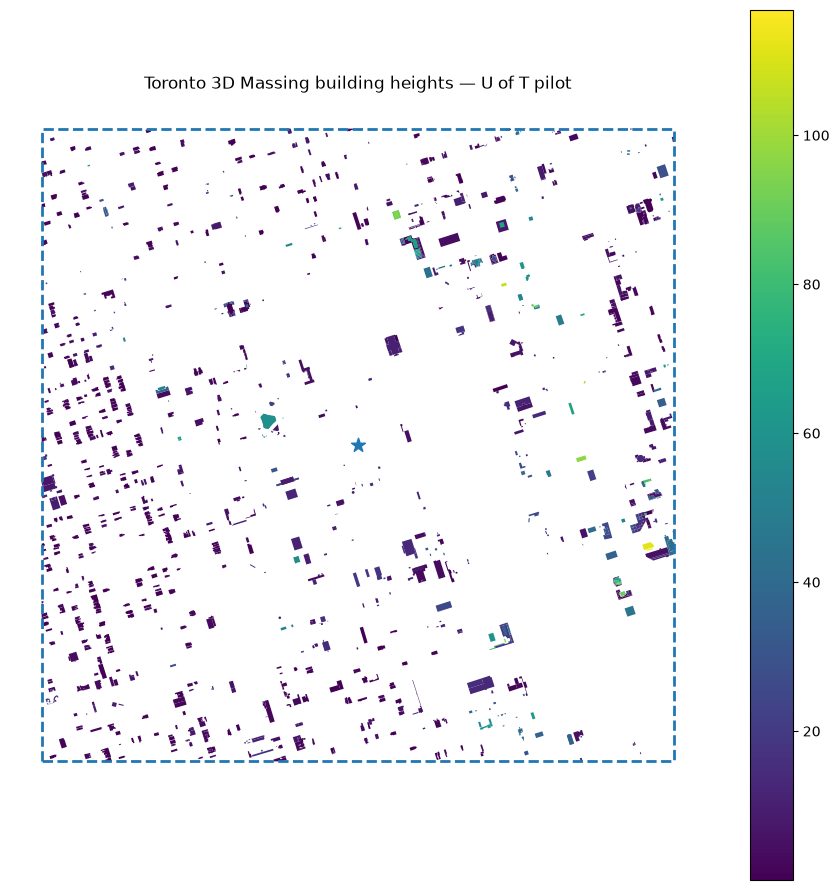

In [13]:
massing_clean_projected = (
    massing_clean.to_crs(
        TARGET_CRS
    )
)

fig, ax = plt.subplots(
    figsize=(9, 9)
)

massing_clean_projected.plot(
    ax=ax,
    column="height_m",
    linewidth=0,
    legend=True,
)

pilot_area.boundary.plot(
    ax=ax,
    linewidth=2.0,
    linestyle="--",
)

campus_center.plot(
    ax=ax,
    marker="*",
    markersize=110,
    zorder=10,
)

ax.set_title(
    "Toronto 3D Massing building heights — U of T pilot"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 14. Prepare a VoxCity-compatible building layer

VoxCity requires WGS84 geometry plus explicit building height information.

We create:

- a simple integer ID;
- `height`;
- `min_height = 0`;
- a clear height-source label.

In [14]:
buildings_voxcity = (
    massing_clean[
        ["height_m", "geometry"]
    ]
    .to_crs(4326)
    .copy()
)

buildings_voxcity["id"] = np.arange(
    1,
    len(buildings_voxcity) + 1,
)

buildings_voxcity["height"] = (
    buildings_voxcity["height_m"]
)

buildings_voxcity["min_height"] = 0.0

buildings_voxcity[
    "height_source"
] = "Toronto 3D Massing 2025"

buildings_voxcity = (
    buildings_voxcity[
        [
            "id",
            "height",
            "min_height",
            "height_source",
            "geometry",
        ]
    ]
)

display(
    buildings_voxcity.head()
)

,id,height,min_height,height_source,geometry
140652,1,1.9524,0.0,Toronto 3D Massing 2025,"POLYGON Z ((-79.39931 43.65486 0, -79.39929 43..."
140650,2,5.6541,0.0,Toronto 3D Massing 2025,"POLYGON Z ((-79.39924 43.65488 0, -79.39923 43..."
141091,3,2.6854,0.0,Toronto 3D Massing 2025,"POLYGON Z ((-79.39314 43.65483 0, -79.39312 43..."
141605,4,3.5424,0.0,Toronto 3D Massing 2025,"POLYGON Z ((-79.39134 43.65487 0, -79.39133 43..."
141284,5,0.3146,0.0,Toronto 3D Massing 2025,"POLYGON Z ((-79.39307 43.65493 0, -79.39306 43..."


## 15. Recreate the same baseline VoxCity pilot

The exact 2 km × 2 km pilot rectangle is passed to VoxCity again so that
baseline and enriched grids have identical geometry and resolution.

INFO | voxcity.voxcity.generator.api | Auto-selecting data sources for: building_source, land_cover_source, canopy_height_source, dem_source, building_complementary_source


Loading formatted geocoded file...


INFO | voxcity.voxcity.generator.api | Detected country for ROI center (-79.3960, 43.6637): Canada
INFO | voxcity.voxcity.generator.api | Selected data sources:
INFO | voxcity.voxcity.generator.api | - Buildings(base)=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Buildings(comp)=Microsoft Building Footprints | https://github.com/microsoft/GlobalMLBuildingFootprints
INFO | voxcity.voxcity.generator.api | - LandCover=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Canopy=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - DEM=Flat
INFO | voxcity.voxcity.generator.api | - ComplementHeight=10
INFO | voxcity.voxcity.utils.cache | Using cached load_land_cover_gdf_from_osm result (d33448b0dc1daece02b9d08e9e4f464f.pkl)
INFO | voxcity.voxcity.utils.cache | Using cached load_gdf_from_openstreetmap result (4ac4ddc186fa955d29f0bd33cef6d27f.pkl)



  • Land Cover:  OpenStreetMap
  • Building:    OpenStreetMap
  • Canopy:      OpenStreetMap
  • DEM:         Flat
------------------------------------------------------------
Downloading... (this may take a moment)
  ✓ Dem complete (1/4)


INFO | voxcity.voxcity.utils.cache | Using cached get_mbfp_gdf result (e38fba154752ce44163df7b4e94dab4c.pkl)
INFO | voxcity.voxcity.geoprocessor.raster.buildings | 2649 of the total 5561 building footprint from the base data source did not have height data.
INFO | voxcity.voxcity.geoprocessor.heights | For 2404 of these building footprints without height, values from the complementary source were assigned.
INFO | voxcity.voxcity.geoprocessor.heights | For 245 of these building footprints without height, no data exist in complementary data.


  ✓ Building complete (2/4)
  Downloaded 2141 individual trees and 5 tree polygons from OSM
  Downloaded 2146 trees from OSM
  Created canopy grids: (408, 408)
  ✓ Canopy complete (3/4)
  ✓ Land Cover complete (4/4)
------------------------------------------------------------
All downloads complete!



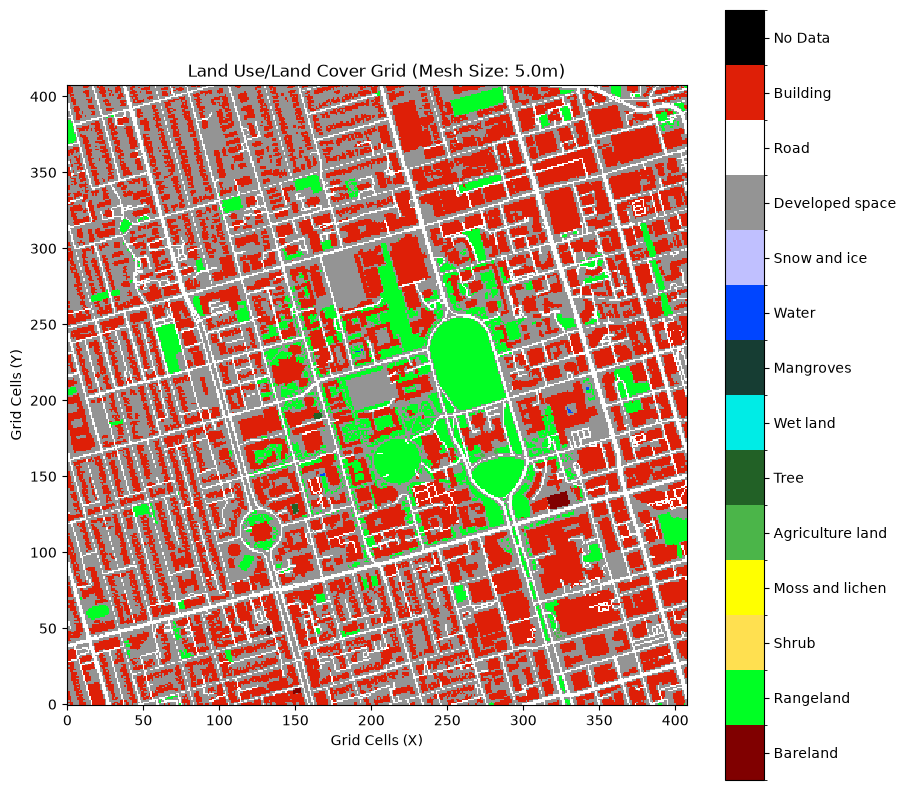

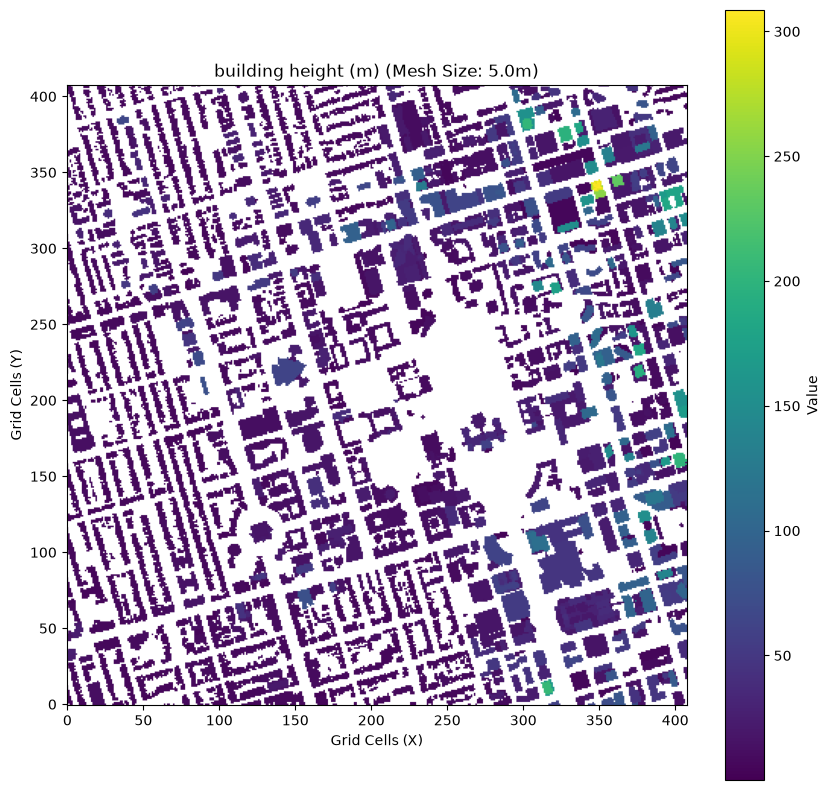

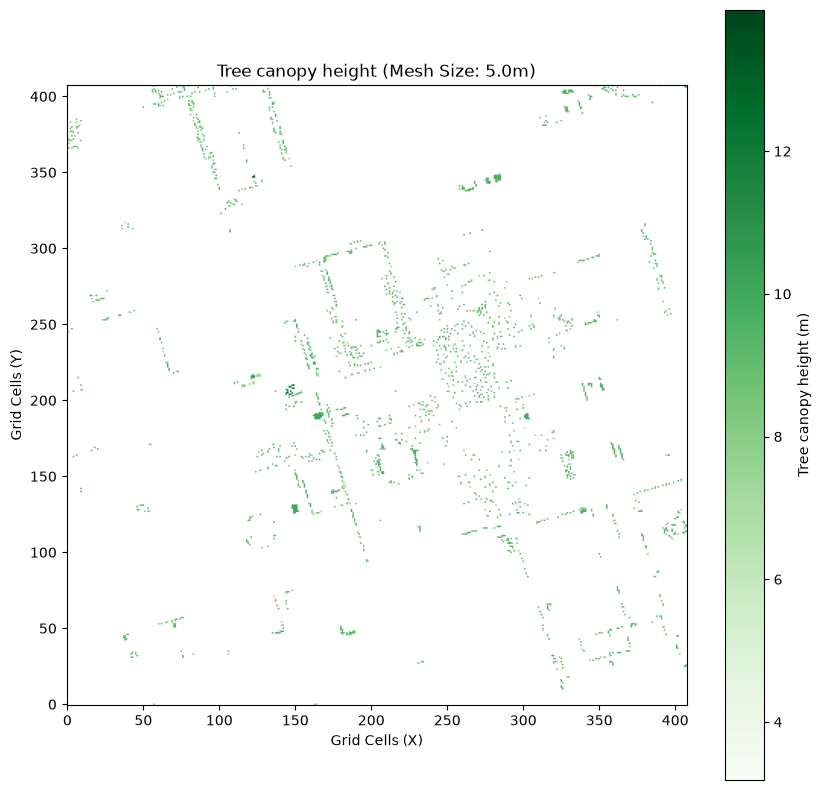

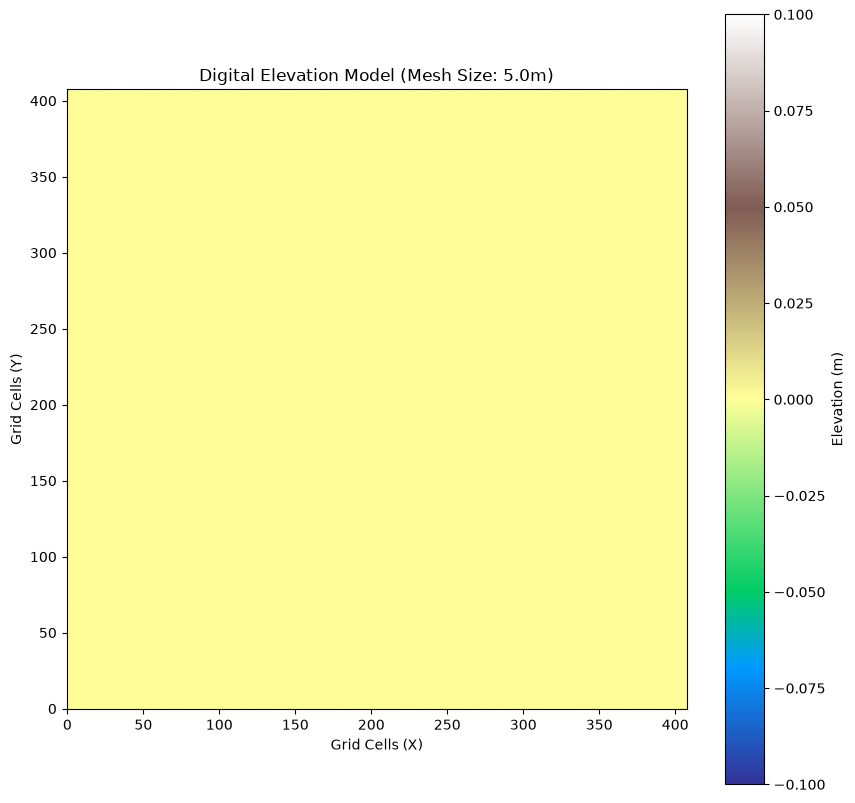

INFO | voxcity.voxcity.generator.voxelizer | Generating 3D voxel data
INFO | voxcity.voxcity.generator.voxelizer | 
Voxel Grid Semantic Codes:
  -3 : Building volume
  -2 : Tree canopy (vegetation)
  -1 : Ground/Subsurface
  >=1: Land cover class at ground surface (see Land Cover Classes)

INFO | voxcity.voxcity.generator.voxelizer | 
VoxCity Standard Land Cover Classes (1-based indices, used in voxel grids):
--------------------------------------------------
   1: Bareland           - Bare soil, rocks, desert
   2: Rangeland          - Grassland, pasture
   3: Shrub              - Shrubland, bushes
   4: Agriculture land   - Cropland, farmland
   5: Tree               - Forest, tree cover
   6: Moss and lichen    - Moss, lichen cover
   7: Wet land           - Wetland, marsh
   8: Mangrove           - Mangrove forest
   9: Water              - Water bodies
  10: Snow and ice       - Snow, ice, glaciers
  11: Developed space    - Urban areas, parking
  12: Road               - Roads, p

VoxCity results saved to output/voxcity.h5
Baseline VoxCity object recreated.


In [15]:
pilot_wgs84 = (
    pilot_area.to_crs(4326)
)

minlon, minlat, maxlon, maxlat = (
    pilot_wgs84.total_bounds
)

rectangle_vertices = [
    (minlon, minlat),
    (minlon, maxlat),
    (maxlon, maxlat),
    (maxlon, minlat),
]

VOXCITY_MESH_M = 5

voxcity_baseline = get_voxcity(
    rectangle_vertices,
    meshsize=VOXCITY_MESH_M,
)

print(
    "Baseline VoxCity object recreated."
)

## 16. Update VoxCity with Toronto municipal building heights

In [16]:
voxcity_enriched = update_voxcity(
    voxcity_baseline,
    building_gdf=buildings_voxcity,
    inplace=False,
)

print(
    "✓ VoxCity building layer updated."
)

INFO | voxcity.voxcity.geoprocessor.raster.buildings | 0 of the total 1212 building footprint from the base data source did not have height data.
INFO | voxcity.voxcity.generator.voxelizer | Generating 3D voxel data
INFO | voxcity.voxcity.generator.voxelizer | 
Voxel Grid Semantic Codes:
  -3 : Building volume
  -2 : Tree canopy (vegetation)
  -1 : Ground/Subsurface
  >=1: Land cover class at ground surface (see Land Cover Classes)

INFO | voxcity.voxcity.generator.voxelizer | 
VoxCity Standard Land Cover Classes (1-based indices, used in voxel grids):
--------------------------------------------------
   1: Bareland           - Bare soil, rocks, desert
   2: Rangeland          - Grassland, pasture
   3: Shrub              - Shrubland, bushes
   4: Agriculture land   - Cropland, farmland
   5: Tree               - Forest, tree cover
   6: Moss and lichen    - Moss, lichen cover
   7: Wet land           - Wetland, marsh
   8: Mangrove           - Mangrove forest
   9: Water             

✓ VoxCity building layer updated.


## 17. Compare baseline and enriched building-height grids

In [17]:
baseline_heights = (
    voxcity_baseline
    .buildings
    .heights
)

enriched_heights = (
    voxcity_enriched
    .buildings
    .heights
)

print(
    "Baseline grid shape:",
    baseline_heights.shape,
)

print(
    "Enriched grid shape:",
    enriched_heights.shape,
)

if (
    baseline_heights.shape
    != enriched_heights.shape
):
    raise RuntimeError(
        "Baseline and enriched grids have different shapes."
    )

building_mask = (
    (baseline_heights > 0)
    |
    (enriched_heights > 0)
)

changed_mask = (
    ~np.isclose(
        baseline_heights,
        enriched_heights,
        equal_nan=True,
    )
)

print(
    "Building cells:",
    int(
        building_mask.sum()
    ),
)

print(
    "Changed cells:",
    int(
        changed_mask.sum()
    ),
)

if building_mask.any():

    difference = (
        enriched_heights[
            building_mask
        ]
        -
        baseline_heights[
            building_mask
        ]
    )

    abs_difference = np.abs(
        difference
    )

    print(
        "Mean absolute difference:",
        round(
            float(
                np.nanmean(
                    abs_difference
                )
            ),
            2,
        ),
        "m",
    )

    print(
        "Median absolute difference:",
        round(
            float(
                np.nanmedian(
                    abs_difference
                )
            ),
            2,
        ),
        "m",
    )

    print(
        "Maximum absolute difference:",
        round(
            float(
                np.nanmax(
                    abs_difference
                )
            ),
            2,
        ),
        "m",
    )

Baseline grid shape: (408, 408)
Enriched grid shape: (408, 408)
Building cells: 68889
Changed cells: 68889
Mean absolute difference: 24.54 m
Median absolute difference: 12.0 m
Maximum absolute difference: 308.6 m


## 18. Compare height distributions

In [18]:
baseline_positive = (
    baseline_heights[
        baseline_heights > 0
    ]
)

enriched_positive = (
    enriched_heights[
        enriched_heights > 0
    ]
)

distribution_summary = pd.DataFrame(
    {
        "baseline": pd.Series(
            baseline_positive
        ).describe(),
        "enriched": pd.Series(
            enriched_positive
        ).describe(),
    }
)

display(
    distribution_summary
)

,baseline,enriched
count,68489.000000,7678.000000
mean,25.628160,10.605198
std,32.986032,17.416699
min,0.100000,0.004000
25%,7.717875,1.203000
50%,12.000000,3.706500
75%,27.000000,11.036000
max,308.600000,116.820000


## 19. Visualize baseline, enriched, and difference grids

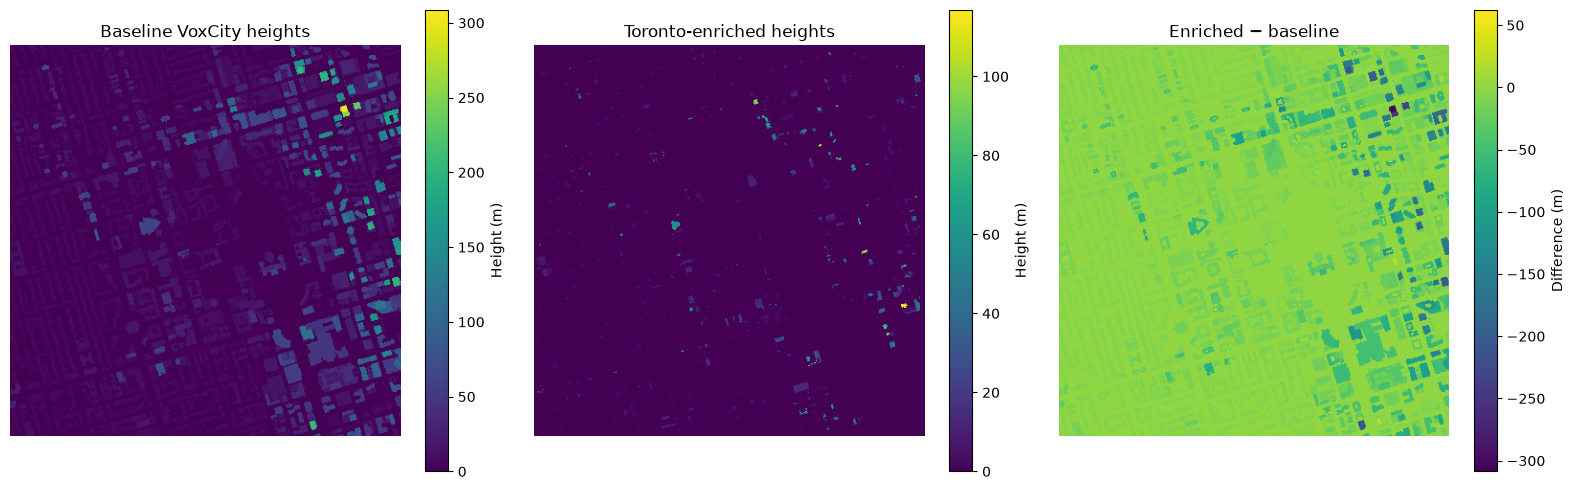

In [19]:
difference_grid = (
    enriched_heights
    -
    baseline_heights
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

im0 = axes[0].imshow(
    baseline_heights,
    origin="lower",
)

axes[0].set_title(
    "Baseline VoxCity heights"
)

plt.colorbar(
    im0,
    ax=axes[0],
    label="Height (m)",
)


im1 = axes[1].imshow(
    enriched_heights,
    origin="lower",
)

axes[1].set_title(
    "Toronto-enriched heights"
)

plt.colorbar(
    im1,
    ax=axes[1],
    label="Height (m)",
)


im2 = axes[2].imshow(
    difference_grid,
    origin="lower",
)

axes[2].set_title(
    "Enriched − baseline"
)

plt.colorbar(
    im2,
    ax=axes[2],
    label="Difference (m)",
)

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 20. Save the clean Toronto building-height layer

In [20]:
buildings_output = (
    ENRICHED_DIR
    / "UOFT_PILOT_buildings_toronto_3d_massing.gpkg"
)

buildings_voxcity.to_file(
    buildings_output,
    driver="GPKG",
)

print(
    "Saved:",
    buildings_output,
)

2026-10-16 01:38:53,889 - INFO - Created 1,212 records


Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_enriched/UOFT_PILOT_buildings_toronto_3d_massing.gpkg


## 21. Save the enriched VoxCity object

In [21]:
enriched_pickle = (
    ENRICHED_DIR
    / "UOFT_PILOT_voxcity_enriched.pkl"
)

save_voxcity(
    enriched_pickle,
    voxcity_enriched,
)

print(
    "Saved:",
    enriched_pickle,
)

INFO | voxcity.voxcity.io | Voxcity data saved to /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_enriched/UOFT_PILOT_voxcity_enriched.pkl


Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_enriched/UOFT_PILOT_voxcity_enriched.pkl


## 22. Save an enriched NetCDF representation

In [22]:
enriched_ds = (
    voxcity_enriched.to_xarray()
)

enriched_ds_to_save = (
    enriched_ds.copy()
)

if (
    "rectangle_vertices"
    in enriched_ds_to_save.attrs
):
    enriched_ds_to_save.attrs[
        "rectangle_vertices"
    ] = json.dumps(
        np.asarray(
            enriched_ds_to_save.attrs[
                "rectangle_vertices"
            ]
        ).tolist()
    )

enriched_nc = (
    ENRICHED_DIR
    / "UOFT_PILOT_voxcity_enriched.nc"
)

enriched_ds_to_save.to_netcdf(
    enriched_nc
)

print(
    "Saved:",
    enriched_nc,
)

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_enriched/UOFT_PILOT_voxcity_enriched.nc


## 23. Final enrichment summary

In [23]:
summary = {
    "pilot_area_km2": (
        pilot_area.geometry.area.iloc[0]
        / 1_000_000
    ),
    "municipal_features_in_pilot": len(
        massing_pilot
    ),
    "clean_buildings_with_height": len(
        massing_clean
    ),
    "selected_height_field": HEIGHT_FIELD,
    "baseline_building_cells": int(
        (baseline_heights > 0).sum()
    ),
    "enriched_building_cells": int(
        (enriched_heights > 0).sum()
    ),
    "changed_grid_cells": int(
        changed_mask.sum()
    ),
}

for key, value in summary.items():
    print(
        f"{key}: {value}"
    )

pilot_area_km2: 4.0
municipal_features_in_pilot: 5452
clean_buildings_with_height: 1212
selected_height_field: MIN_HEIGHT
baseline_building_cells: 68489
enriched_building_cells: 7678
changed_grid_cells: 68889


## Interpretation and next step

This notebook should establish whether Toronto's municipal 3D Massing data
provide a substantially better building-height representation than the baseline
VoxCity model around U of T.

Before proceeding, verify:

- the selected height field is truly building height;
- its unit is metres;
- the mapped height pattern is plausible;
- extreme values correspond to real tall buildings rather than data errors;
- the enriched VoxCity grid changes in a physically sensible way.

If those checks pass, the next notebook is:

**`04_toronto_prepare_solweig_inputs.ipynb`**

That stage will convert the enriched pilot VoxCity model into projected DSM,
canopy, and terrain rasters suitable for SOLWEIG.